In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import json
from pathlib import Path
from datasets import Dataset

DATA_PATH = Path("/content/drive/MyDrive/ctp/dapt_chunks.jsonl")

data = []

with DATA_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        data.append(json.loads(line))

dataset = Dataset.from_list(data)

print(dataset)

Dataset({
    features: ['text', 'sources'],
    num_rows: 65
})


In [ ]:
!pip -q install -U transformers datasets accelerate peft trl bitsandbytes sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 118.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 18.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
!pip -q install unsloth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.4/82.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 120.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 100.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 112.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 109.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 21.9 MB/s eta 0:00:00


In [ ]:
from unsloth import FastLanguageModel

MODEL_ID = "unsloth/Qwen2.5-0.5B"
MAX_SEQ_LENGTH = 1024

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_ID,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
)

print("Base model and tokenizer loaded successfully.")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Base model and tokenizer loaded successfully.


In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=[
        "q_proj","k_proj","v_proj","o_proj",
        "gate_proj","up_proj","down_proj",
    ],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
)

model.print_trainable_parameters()

Unsloth 2026.10.3 patched 24 layers with 24 QKV layers, 24 O layers and 24 MLP layers.


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


In [ ]:
lengths = [
    len(tokenizer(text, add_special_tokens=True)["input_ids"])
    for text in dataset["text"]
]

print("Number of chunks:", len(lengths))
print("Shortest:", min(lengths))
print("Median:", sorted(lengths)[len(lengths) // 2])
print("Longest:", max(lengths))
print("Chunks over 1024:", sum(n > 1024 for n in lengths))
print("Chunks over 1800:", sum(n > 1800 for n in lengths))
print("Chunks over 2048:", sum(n > 2048 for n in lengths))

Number of chunks: 65
Shortest: 99
Median: 479
Longest: 917
Chunks over 1024: 0
Chunks over 1800: 0
Chunks over 2048: 0


In [ ]:
print("dataset exists:", "dataset" in globals())
print("tokenizer exists:", "tokenizer" in globals())
print("tokenized exists:", "tokenized" in globals())
print("lm_dataset exists:", "lm_dataset" in globals())

dataset exists: True
tokenizer exists: True
tokenized exists: False
lm_dataset exists: False


In [ ]:
MAX_SEQ_LENGTH = 1024
BATCH_SIZE = 8

input_ids_buffer = []
packed_sequences = []

for start in range(0, len(dataset), BATCH_SIZE):
    batch = dataset[start : start + BATCH_SIZE]
    texts = [
        text.rstrip() + tokenizer.eos_token
        for text in batch["text"]
    ]

    encoded = tokenizer(
        texts,
        add_special_tokens=False,
        truncation=False,
    )

    input_ids_buffer.extend(
        token_id
        for sequence in encoded["input_ids"]
        for token_id in sequence
    )

    while len(input_ids_buffer) >= MAX_SEQ_LENGTH:
        packed_sequences.append({
            "input_ids": input_ids_buffer[:MAX_SEQ_LENGTH],
            "labels": input_ids_buffer[:MAX_SEQ_LENGTH].copy(),
        })
        input_ids_buffer = input_ids_buffer[MAX_SEQ_LENGTH:]

    print(f"Processed {min(start + BATCH_SIZE, len(dataset))}/{len(dataset)} chunks")

from datasets import Dataset

lm_dataset = Dataset.from_list(packed_sequences)

print("Packed sequences:", len(lm_dataset))
print("Unused leftover tokens:", len(input_ids_buffer))

Processed 8/65 chunks
Processed 16/65 chunks
Processed 24/65 chunks
Processed 32/65 chunks
Processed 40/65 chunks
Processed 48/65 chunks
Processed 56/65 chunks
Processed 64/65 chunks
Processed 65/65 chunks
Packed sequences: 31
Unused leftover tokens: 863


In [ ]:
print("Packed sequences:", len(lm_dataset))
print("Columns:", lm_dataset.column_names)
print("First sequence length:", len(lm_dataset[0]["input_ids"]))
print("First labels length:", len(lm_dataset[0]["labels"]))

assert len(lm_dataset) == 31
assert len(lm_dataset[0]["input_ids"]) == 1024
assert len(lm_dataset[0]["labels"]) == 1024

print("Verification passed.")

Packed sequences: 31
Columns: ['input_ids', 'labels']
First sequence length: 1024
First labels length: 1024
Verification passed.


In [ ]:
import torch
from transformers import Trainer, TrainingArguments
from transformers import DataCollatorForLanguageModeling

OUTPUT_DIR = "/content/drive/MyDrive/ctp/studymate-dapt"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    num_train_epochs=3,
    learning_rate=2e-5,
    warmup_steps=2,
    logging_steps=1,
    save_strategy="epoch",
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    optim="adamw_torch",
    report_to="none",
    seed=3407,
)

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=lm_dataset,
    data_collator=data_collator,
)

print("Trainer configured successfully.")
print("Training examples:", len(lm_dataset))
print("Epochs:", training_args.num_train_epochs)
print("Effective batch size:", 1 * 4)
print("Output directory:", OUTPUT_DIR)

Trainer configured successfully.
Training examples: 31
Epochs: 3
Effective batch size: 4
Output directory: /content/drive/MyDrive/ctp/studymate-dapt


In [ ]:
train_result = trainer.train()

print("\nDAPT training completed.")
print("Training loss:", train_result.training_loss)
print("Training steps:", train_result.global_step)

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 31 | Num Epochs = 3 | Total steps = 24
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 4 x 1) = 4
 "-____-"     Trainable parameters = 8,798,208 of 502,830,976 (1.75% trained)


Step,Training Loss
1,3.173180
2,3.059680
3,3.172779
4,3.680724
5,3.030681
6,2.988540
7,3.126084
8,3.265239
9,3.278791
10,3.592891


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-dapt/checkpoint-8/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-dapt/checkpoint-16/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-dapt/checkpoint-24/tokenizer_config.json.



DAPT training completed.
Training loss: 3.162286857763926
Training steps: 24


In [ ]:
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("DAPT adapter and tokenizer saved to:", OUTPUT_DIR)

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-dapt/tokenizer_config.json.


DAPT adapter and tokenizer saved to: /content/drive/MyDrive/ctp/studymate-dapt


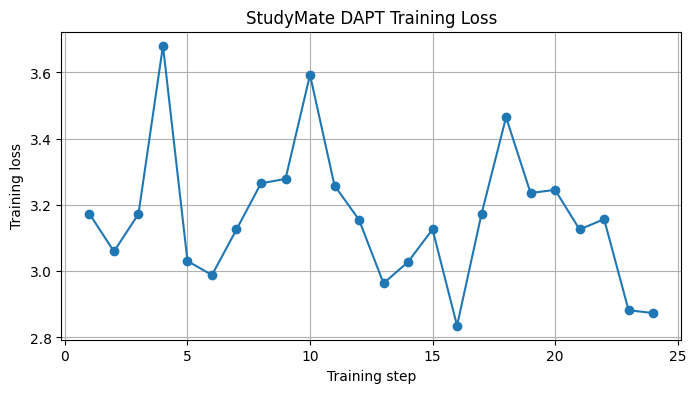

In [ ]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

steps = [
    item["step"] for item in logs
    if "loss" in item and "step" in item
]
losses = [
    item["loss"] for item in logs
    if "loss" in item and "step" in item
]

plt.figure(figsize=(8, 4))
plt.plot(steps, losses, marker="o")
plt.xlabel("Training step")
plt.ylabel("Training loss")
plt.title("StudyMate DAPT Training Loss")
plt.grid(True)
plt.show()

In [ ]:
!pip install -q -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 15.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.17.0 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.


In [ ]:
from huggingface_hub import login, whoami

login()

print("Authenticated Hugging Face account:", whoami()["name"])

Authenticated Hugging Face account: ksumanthreddy96


In [ ]:
from huggingface_hub import HfApi, whoami

api = HfApi()
print("Logged-in account:", whoami()["name"])

HF_REPO_ID = "ksumanthreddy96/studymate-ctp-dapt"

# Create the repository under the intended account
api.create_repo(
    repo_id=HF_REPO_ID,
    repo_type="model",
    exist_ok=True,
)

# Upload saved files directly, bypassing trainer.push_to_hub()
api.upload_folder(
    folder_path=OUTPUT_DIR,
    repo_id=HF_REPO_ID,
    repo_type="model",
    ignore_patterns=["checkpoint-*"],
)

print("Repository:", f"https://huggingface.co/{HF_REPO_ID}")

Logged-in account: ksumanthreddy96
Repository: https://huggingface.co/ksumanthreddy96/studymate-ctp-dapt
